In [28]:
import h5py # package was installed and found for hdf5 format

from matplotlib import pyplot as plt
import matplotlib.colors as colors
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import warnings
from astropy import units as u, constants as const
from meshoid import Meshoid, load_from_snapshot
%matplotlib inline

from os.path import isfile
from urllib.request import urlretrieve
import shutil 

url_base =  "https://users.flatironinstitute.org/~mgrudic/starforge_data/STARFORGE_RT/"

# /mnt/ceph/users/starforge/STARFORGE_RT/STARFORGE_v1.3/M2e4_R10/M2e4_R10_Z1_S0_A2_B0.1_I1_Res126_n2_sol0.5_42/output
run = "STARFORGE_v1.3/M2e4_R10/M2e4_R10_Z1_S0_A2_B0.1_I1_Res126_n2_sol0.5_42/output/"
print(url_base + run)
data_dir = 'M2e4_R10/'

ndigits = 4  # numbers of digits in filename
has_zeros = False

https://users.flatironinstitute.org/~mgrudic/starforge_data/STARFORGE_RT/STARFORGE_v1.3/M2e4_R10/M2e4_R10_Z1_S0_A2_B0.1_I1_Res126_n2_sol0.5_42/output/


In [27]:
# the raytracer below cannot cache its compiled kernel, which is harmless here
warnings.filterwarnings("ignore", message=".*Cannot cache compiled function.*")

# coordinates for a square map, for pcolormesh
def grid(halfwidth, res):
    a = np.linspace(-halfwidth, halfwidth, res)
    return np.meshgrid(a, a, indexing="ij")

def chck_snap(SNAPFILE):
    F = h5py.File(SNAPFILE,'r')
    print(list(F.keys()))   # if we don't see PartType5, then we don't have sinks
    F.close()

# check dimension of metalicity of gas to see if jet fraction is in there
def chck_z(SNAPFILE):
    with h5py.File(SNAPFILE,"r") as F:
        z_gas = F["PartType0/Metallicity"][:]
        print(z_gas.shape)  # yay if 14! 

def chck_units(SNAPFILE):
    # get some units!
    with h5py.File(SNAPFILE,"r") as F:
        header = F["Header"]
        unit_length = F["Header"].attrs["UnitLength_In_CGS"]*u.cm   # is 1pc
        unit_mass = F["Header"].attrs["UnitMass_In_CGS"] * u.g   # is 1msol
        unit_velocity = F["Header"].attrs["UnitVelocity_In_CGS"] * u.cm / u.s   # is 100 cm/s  = 1 m/s
        unit_density = unit_mass / unit_length**3
        print(unit_length)
        print(unit_mass)
        print(unit_velocity)

        code_time_to_Myr = (u.pc/(u.m/u.s)).to('Myr')
        time_Myr = F["Header"].attrs['Time'] *code_time_to_Myr
        print('snap time {:.3f} Myr'.format(time_Myr)) # timestamp of this snapshot

def read_in_stuff(SNAPFILE):
    with h5py.File(SNAPFILE,"r") as F:
        z_gas = F["PartType0/Metallicity"][:]  # get jet fractions 
        print('z_gas shape',z_gas.shape)  # yay 14 big
        f_jet = z_gas[:,11]  # jet fraction 
        #f_jet = 0 
        x_gas = F["PartType0/Coordinates"][:]  # get gas coordinates
        v_gas = F["PartType0/Velocities"][:]  # get gas velocities
        v2_gas = np.sum(v_gas*v_gas, axis=1)
        va_gas = np.sqrt(v2_gas)  # |v| for gas 

        try:
            x_part = F["PartType5/Coordinates"][:]   # get sink particle coordinates
            print('x_part shape',x_part.shape)  # we only have a thousand or so sinks
            v_part = F["PartType5/Velocities"][:]  # get particle velocities
            md_part = F["PartType5/BH_Mdot"][:]   # accretion rate?
            j_part =  F["PartType5/BH_Specific_AngMom"][:]   # angular momentum vector 
        except: 
            x_part = []
            v_part = []
            md_part = []
            j_part = []
        
    return x_gas,v_gas,z_gas,f_jet,va_gas,x_part,v_part,md_part,j_part


In [21]:

# these are only 350 MByte! res is low and we could try things quickly 
#SNAPFILE = 'snapshot_6240.hdf5'  
SNAPFILE = 'snapshot_2100.hdf5' 
URL = url_base + run + SNAPFILE
urlretrieve(URL, SNAPFILE)  # is 350MBytes
shutil.move(SNAPFILE, data_dir+SNAPFILE)

# I downloaded 1400 - 3300 and put in subdirectory

https://users.flatironinstitute.org/~mgrudic/starforge_data/STARFORGE_RT/STARFORGE_v1.3/M2e4_R10/M2e4_R10_Z1_S0_A2_B0.1_I1_Res126_n2_sol0.5_42/output/


('snapshot_2100.hdf5', <http.client.HTTPMessage at 0x162772c10>)

In [ ]:

def mkfilename(data_dir,index):
    ifile = ""
    if (has_zeros==True):
        for k in range(ndigits):
            if (index < 10**k):
                ifile = ifile + '0'
    ifile += '{:d}'.format(index)
    snapfile = data_dir + 'snapshot_' + ifile + '.hdf5'
    print(snapfile)
    return snapfile

def mkpngfname(index,front,back):
    ifile = ""
    for k in range(ndigits):
        if (index < 10**k):
            ifile = ifile + '0'
    ifile += '{:d}'.format(index)
    filename = front + ifile + back
    print(filename)
    return filename

if (1==0): #tests
    mkpngfname(200,'junk_','.png')
    mkfilename('',2300)

In [14]:
for k in range(1400,3400,100):
    snapfile = mkfilename(data_dir,k)
    chck_snap(snapfile)
    #chck_units(snapfile) 
    chck_z(snapfile)

M2e4_R10/snapshot_1400.hdf5
['Header', 'PartType0', 'PartType5']
(2473176, 14)
M2e4_R10/snapshot_1500.hdf5
['Header', 'PartType0', 'PartType5']
(2471810, 14)
M2e4_R10/snapshot_1600.hdf5
['Header', 'PartType0', 'PartType5']
(2470275, 14)
M2e4_R10/snapshot_1700.hdf5
['Header', 'PartType0', 'PartType5']
(2468258, 14)
M2e4_R10/snapshot_1800.hdf5
['Header', 'PartType0', 'PartType5']
(2466450, 14)
M2e4_R10/snapshot_1900.hdf5
['Header', 'PartType0', 'PartType5']
(2465035, 14)
M2e4_R10/snapshot_2000.hdf5
['Header', 'PartType0', 'PartType5']
(2462645, 14)
M2e4_R10/snapshot_2100.hdf5
['Header', 'PartType0', 'PartType5']
(2457072, 14)
M2e4_R10/snapshot_2200.hdf5
['Header', 'PartType0', 'PartType5']
(2447573, 14)
M2e4_R10/snapshot_2300.hdf5
['Header', 'PartType0', 'PartType5']
(2442108, 14)
M2e4_R10/snapshot_2400.hdf5
['Header', 'PartType0', 'PartType5']
(2437267, 14)
M2e4_R10/snapshot_2500.hdf5
['Header', 'PartType0', 'PartType5']
(2429279, 14)
M2e4_R10/snapshot_2600.hdf5
['Header', 'PartType0', 

In [13]:
snapfile = mkfilename(data_dir,3000)
chck_z(snapfile)
with h5py.File(snapfile,"r") as F:
    print(list(F['PartType0'].keys()))
    z_gas = F["PartType0/Metallicity"][:]
    print(z_gas.shape)

M2e4_R10/snapshot_3000.hdf5
(2380960, 14)
['Coordinates', 'Density', 'DustToGasRatio_Local', 'Dust_Temperature', 'ElectronAbundance', 'HII', 'IRBand_Radiation_Temperature', 'InternalEnergy', 'MagneticField', 'Masses', 'Metallicity', 'MolecularMassFraction', 'NeutralHydrogenAbundance', 'ParticleChildIDsNumber', 'ParticleIDGenerationNumber', 'ParticleIDs', 'PhotonEnergy', 'PhotonFluxDensity', 'Potential', 'Pressure', 'SmoothingLength', 'Temperature', 'Velocities']
(2380960, 14)


M2e4_R10/snapshot_1400.hdf5
z_gas shape (2473176, 14)
x_part shape (13, 3)


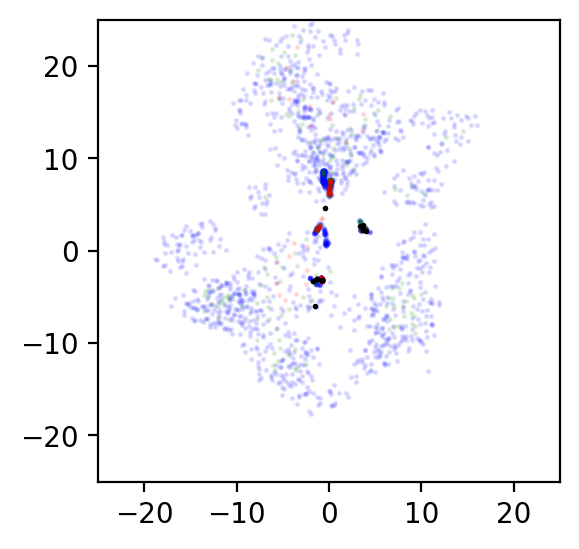

In [19]:


def plt1(SNAPFILE,ofile=""):
    x_gas,v_gas,z_gas,f_jet,va_gas,x_part,v_part,md_part,j_part=read_in_stuff(SNAPFILE)
    c0x = 50
    c0y=  50
    
    fig,ax = plt.subplots(1,1,figsize=(3,3),dpi=200)

    junk = np.logical_and(va_gas>10000,va_gas<20000)
    x_jet = x_gas[junk,0] - c0x
    y_jet = x_gas[junk,1] - c0y
    ax.scatter(x_jet,y_jet,s=1,color='blue',alpha=0.1)
    
    junk = np.logical_and(va_gas>20000,va_gas<30000)
    x_jet = x_gas[junk,0] - c0x
    y_jet = x_gas[junk,1] - c0y
    ax.scatter(x_jet,y_jet,s=1,color='green',alpha=0.1)

    junk = np.logical_and(va_gas>30000,va_gas<40000)
    x_jet = x_gas[junk,0] - c0x
    y_jet = x_gas[junk,1] - c0y
    ax.scatter(x_jet,y_jet,s=1,color='red',alpha=0.1)
    
    try:
        ax.scatter(x_part[:,0]-c0x,x_part[:,1]-c0y,s=1,color='black')
    except:
        z=0
    xmax = 25
    ax.set_xlim([-xmax,xmax])
    ax.set_ylim([-xmax,xmax])
    ax.set_aspect(1)
    if (len(ofile)>3):
        plt.savefig(ofile)
    
    plt.show()


if (1==0):
    SNAPFILE = mkfilename(data_dir,1400) 
    plt1(SNAPFILE)

M2e4_R10/snapshot_1200.hdf5
z_gas shape (2473408, 14)
x_part shape (5, 3)


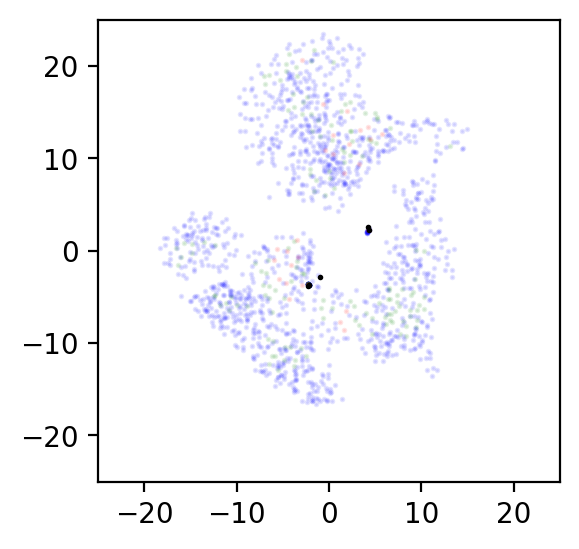

M2e4_R10/snapshot_1300.hdf5
z_gas shape (2473381, 14)
x_part shape (7, 3)


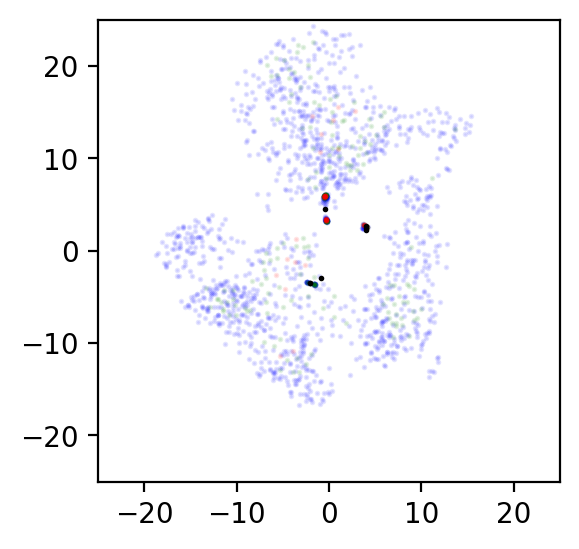

M2e4_R10/snapshot_1400.hdf5
z_gas shape (2473176, 14)
x_part shape (13, 3)


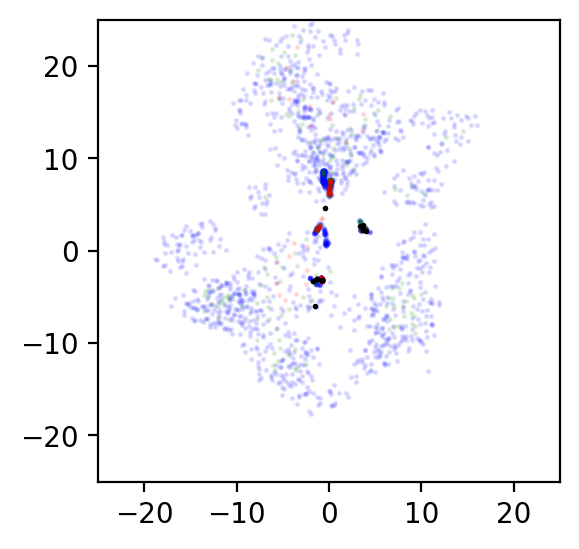

M2e4_R10/snapshot_1500.hdf5
z_gas shape (2471810, 14)
x_part shape (16, 3)


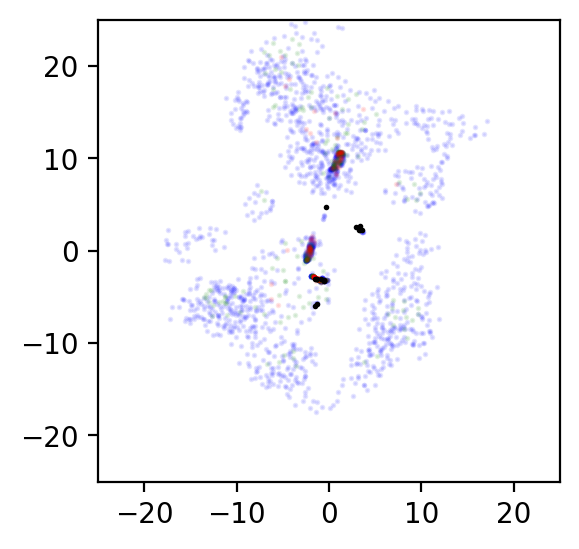

M2e4_R10/snapshot_1600.hdf5
z_gas shape (2470275, 14)
x_part shape (22, 3)


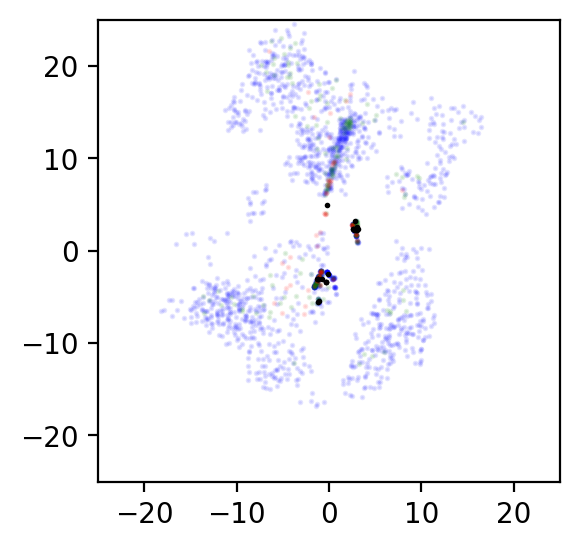

M2e4_R10/snapshot_1700.hdf5
z_gas shape (2468258, 14)
x_part shape (29, 3)


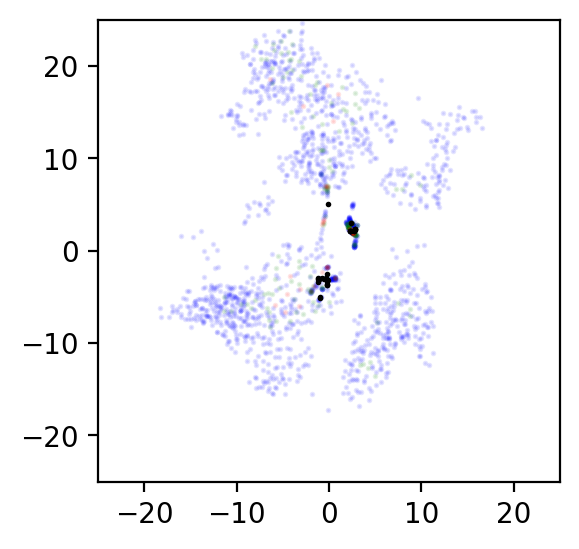

M2e4_R10/snapshot_1800.hdf5
z_gas shape (2466450, 14)
x_part shape (40, 3)


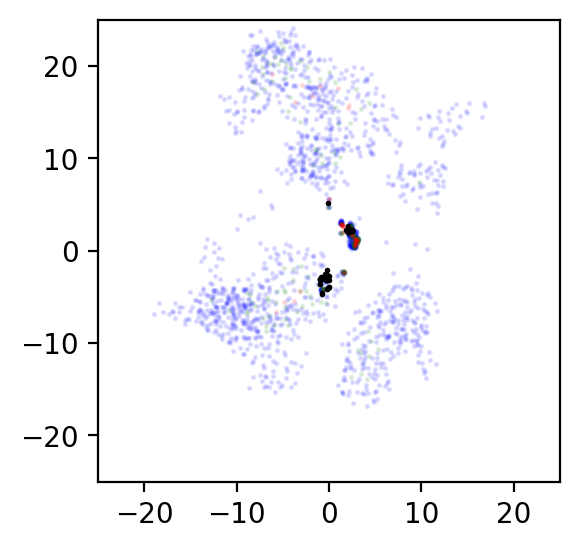

M2e4_R10/snapshot_1900.hdf5
z_gas shape (2465035, 14)
x_part shape (50, 3)


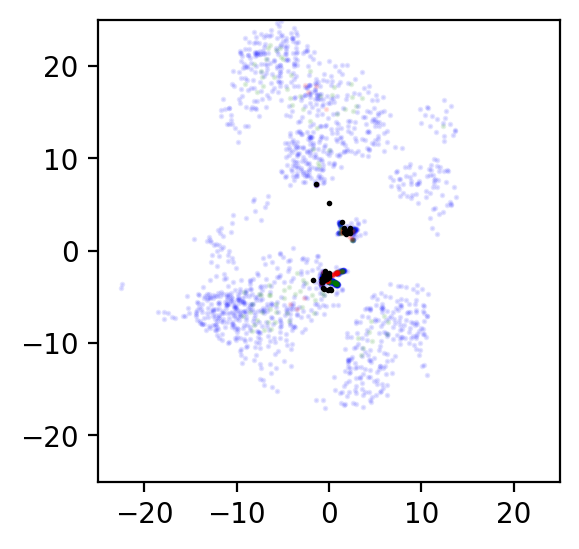

M2e4_R10/snapshot_2000.hdf5
z_gas shape (2462645, 14)
x_part shape (70, 3)


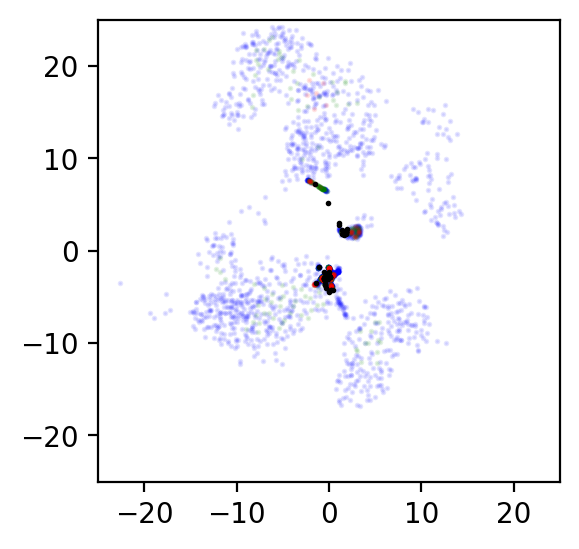

M2e4_R10/snapshot_2100.hdf5
z_gas shape (2457072, 14)
x_part shape (84, 3)


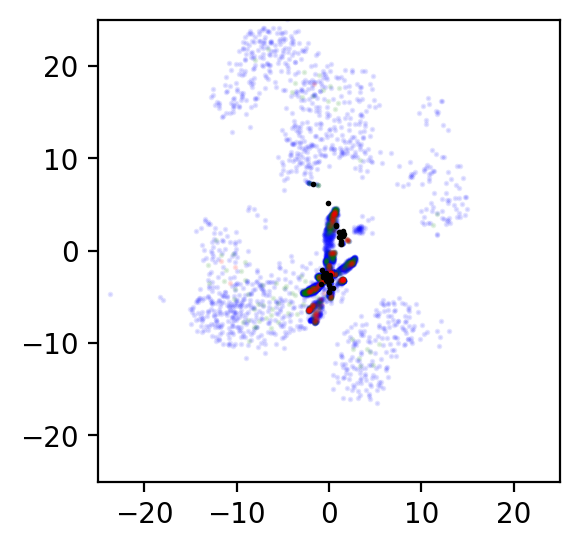

M2e4_R10/snapshot_2200.hdf5
z_gas shape (2447573, 14)
x_part shape (101, 3)


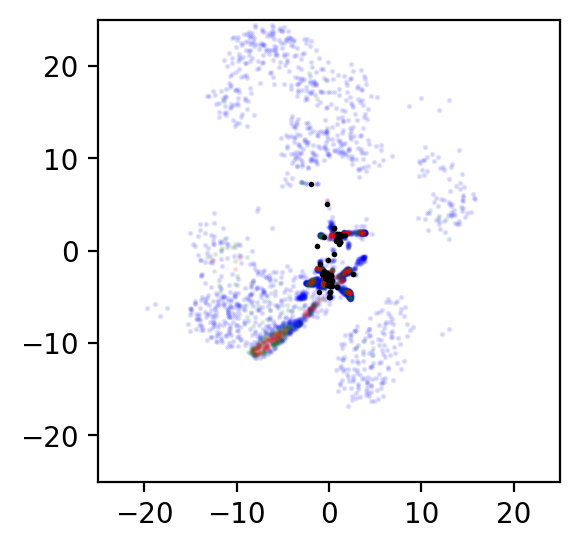

M2e4_R10/snapshot_2300.hdf5
z_gas shape (2442108, 14)
x_part shape (106, 3)


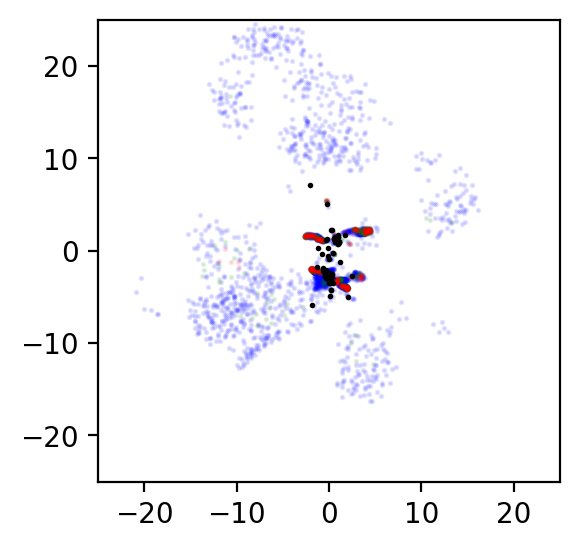

M2e4_R10/snapshot_2400.hdf5
z_gas shape (2437267, 14)
x_part shape (131, 3)


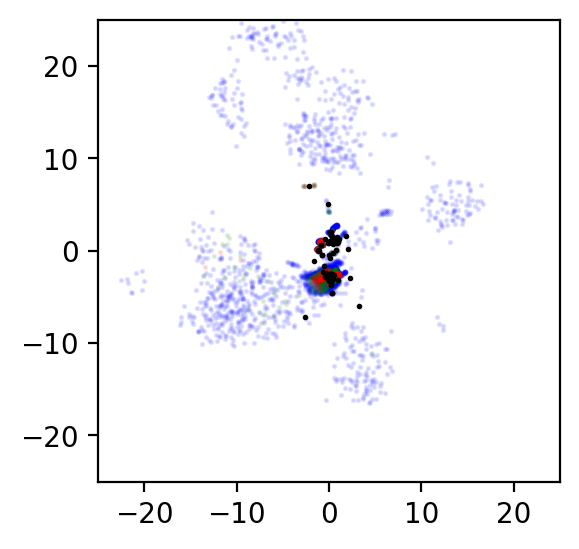

M2e4_R10/snapshot_2500.hdf5
z_gas shape (2429279, 14)
x_part shape (158, 3)


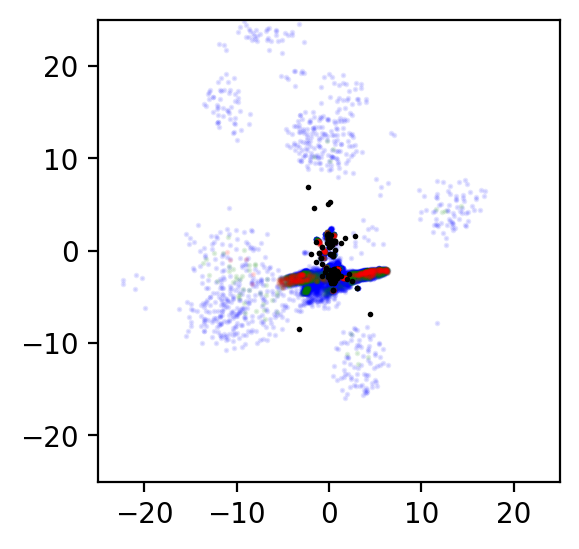

M2e4_R10/snapshot_2600.hdf5
z_gas shape (2420120, 14)
x_part shape (176, 3)


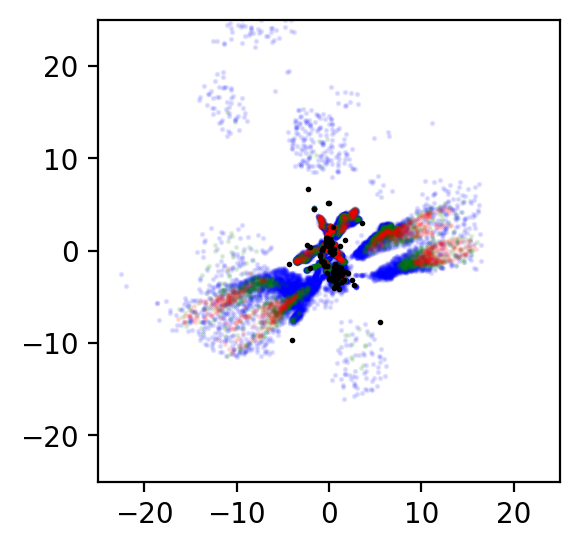

M2e4_R10/snapshot_2700.hdf5
z_gas shape (2402662, 14)
x_part shape (181, 3)


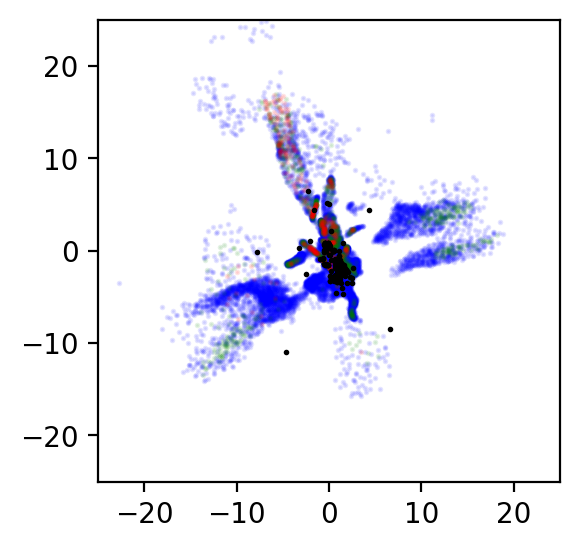

M2e4_R10/snapshot_2800.hdf5
z_gas shape (2392503, 14)
x_part shape (194, 3)


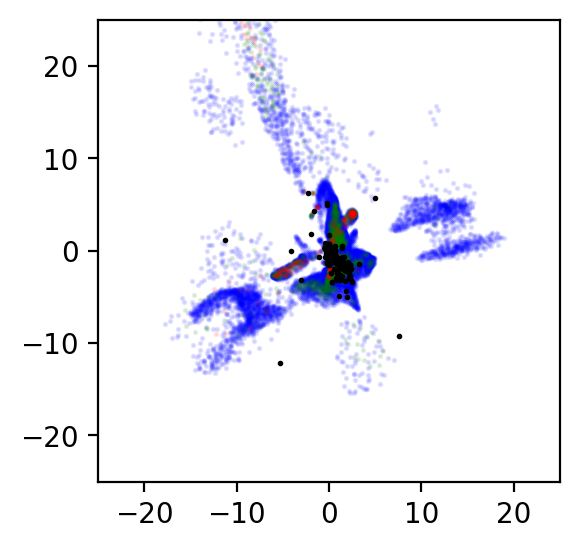

M2e4_R10/snapshot_2900.hdf5
z_gas shape (2385250, 14)
x_part shape (210, 3)


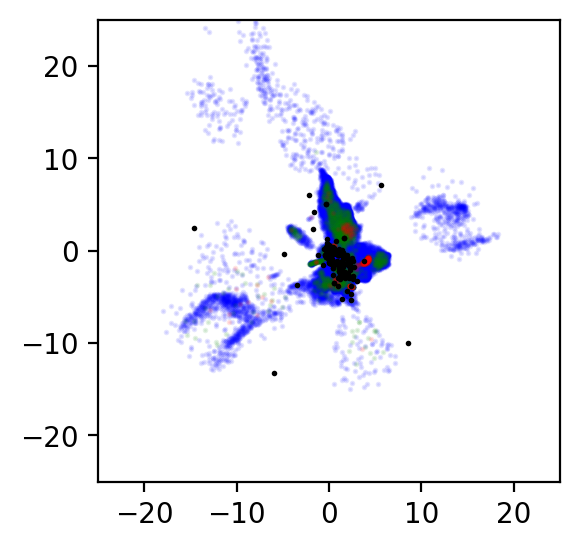

M2e4_R10/snapshot_3000.hdf5
z_gas shape (2380960, 14)
x_part shape (221, 3)


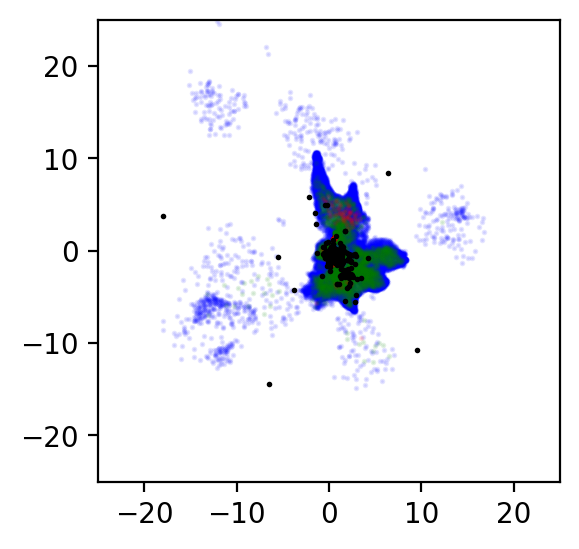

M2e4_R10/snapshot_3100.hdf5
z_gas shape (2376849, 14)
x_part shape (237, 3)


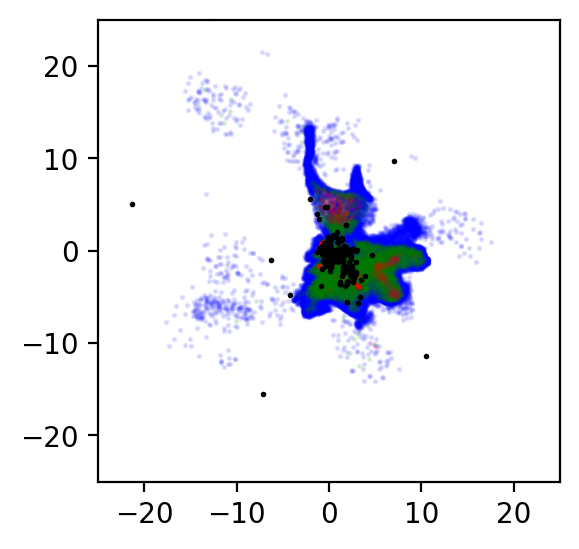

M2e4_R10/snapshot_3200.hdf5
z_gas shape (2371836, 14)
x_part shape (248, 3)


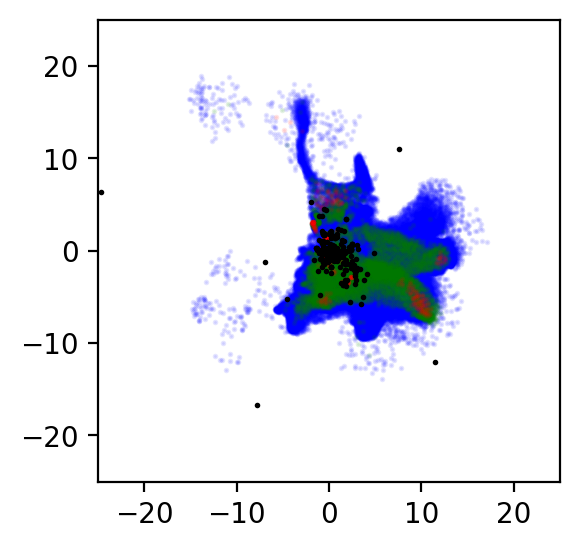

M2e4_R10/snapshot_3300.hdf5
z_gas shape (2366393, 14)
x_part shape (258, 3)


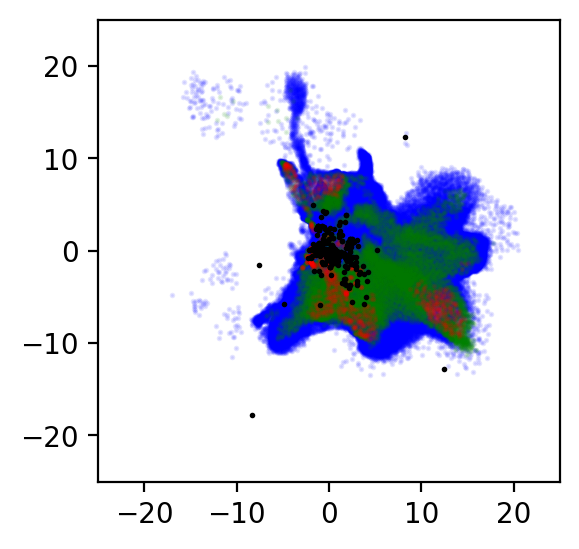

In [23]:
for k in range(1200,3400,100):
    snapfile = mkfilename(data_dir,k)
    plt1(snapfile)
    